<a href="https://colab.research.google.com/github/andrearuvalcaba6445-netizen/Tareas/blob/main/Proyecto_Indoor_Scenes/Indoor_scenes_U3_Teoria_Transfer_Learning__corregido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Deep Learning para visión de computadoras
##Lab 3.1 Transferencia de aprendizaje en visión

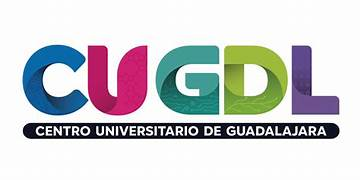

#Parte A https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

[Notas CS231n: *Transfer Learning*](https://cs231n.github.io/transfer-learning/)

[Modelos](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)


# Extración de caracteristicas
Transformación de los datos brutos en un conjunto de características significativas, captando la información esencial y reduciendo al mismo tiempo la redundancia.



#Aprendizaje por transferencia
En la práctica, muy pocas personas entrenan una red neuronal convolucional completa desde cero (con inicialización aleatoria), ya que es relativamente raro contar con un conjunto de datos de tamaño suficiente. En cambio, es común preentrenar una red neuronal convolucional en un conjunto de datos muy grande (por ejemplo, ImageNet, que contiene 1,2 millones de imágenes con 1000 categorías) y luego usar la red neuronal convolucional como inicialización o como extractor de características fijas para la tarea de interés.

Las CNN aprenden características a través de su estructura jerárquica. En las primeras capas, detectan elementos visuales básicos, como bordes y colores. A continuación, las capas intermedias combinan estos elementos para reconocer patrones y formas, mientras que las capas más profundas captan objetos complejos y permiten comprender la escena.

![Texto que aparece si no se puede mostrar la imagen](https://media.datacamp.com/cms/ad_4nxdjeei1g5rxiuqeybgsim6rnc1jef-c90ltf0e-eui0qreoicp_kizwnhd6nvdsway2r9kxmsynco8wzaanwobvd3b7pbda6_ddk47xhrst-h-gi5wmsqq5xpa0fpq_oh4pbf6b.jpeg)



![Texto que aparece si no se puede mostrar la imagen](https://svitla.com/wp-content/uploads/2024/06/Feature-maps-at-different-stages-on-the-network.webp)

*   **ConvNet como extractor de características fijas**

Toma una ConvNet preentrenada en ImageNet, elimina la última capa totalmente conectada (las salidas de esta capa son las puntuaciones de 1000 clases para una tarea diferente como ImageNet), luego trata el resto de la ConvNet como un extractor de características fijas para el nuevo conjunto de datos

AlexNet calcularía un vector de 4096-D para cada imagen que contiene las activaciones de la capa oculta inmediatamente anterior al clasificador

![Texto que aparece si no se puede mostrar la imagen](https://miro.medium.com/v2/resize:fit:1200/1*0dsWFuc0pDmcAmHJUh7wqg.png)

*   **Ajuste fino (pesos) de la ConvNet**

La segunda estrategia consiste no solo en reemplazar y reentrenar el clasificador sobre la ConvNet en el nuevo conjunto de datos, sino también en ajustar los pesos de la red preentrenada continuando la retropropagación.


![Texto que aparece si no se puede mostrar la imagen](https://libros.catedu.es/uploads/images/gallery/2023-10/scaled-1680-/zr1image.png)

![Texto que aparece si no se puede mostrar la imagen](https://tse2.mm.bing.net/th/id/OIP.g1h_OTPDiPasK6FzK83F4AHaEN?r=0&pid=Api&h=220&P=0)


![Texto que aparece si no se puede mostrar la imagen](https://i.ytimg.com/vi/3gyeDlZqWko/maxresdefault.jpg)


## Librerías

In [ ]:
import os, time, copy, zipfile, urllib.request, warnings      #descarga y manejo de zip
import numpy as np, pandas as pd, matplotlib.pyplot as plt    #datos tabulares
import torch, torch.nn as nn, torch.nn.functional as F        #componentes básicos para bloques en redes neuronales y funciones (activación, funciones de pérdida y operaciones de convolución)
import torchvision                                            #datasets, operaciones sobre imagenes
from torchvision import datasets, models, transforms
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from IPython.display import display
warnings.filterwarnings("ignore")

torch.manual_seed(0); np.random.seed(0)                       #semilla
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| dispositivo:", DEVICE)

PyTorch 2.11.0+cpu | torchvision 0.26.0+cpu | dispositivo: cpu


# Dataset

Utilizaremos las bibliotecas `datasets` (Hugging Face), `torchvision` y `torch.utils.data` para cargar los datos.

El problema que vamos a resolver hoy es entrenar un modelo para **clasificar escenas de interiores** (dormitorio, cocina, baño, sala, etc.) a partir de una fotografía. El dataset es [`FatimaSaadNaik/indoor-scenes-dataset`](https://huggingface.co/datasets/FatimaSaadNaik/indoor-scenes-dataset).

A diferencia de un problema de objetos (hormigas vs. abejas), aquí hay **muchas clases** y la etiqueta depende de la *escena completa* y no de un objeto centrado. Esto lo hace un buen caso para discutir la similitud de dominio con ImageNet.

Para que los experimentos corran rápido (y para simular un escenario de **pocos datos**) usamos una submuestra de `N_TRAIN_POR_CLASE` imágenes de entrenamiento por clase. Pon `None` para usar todo el conjunto.

In [ ]:
# Login using e.g. `huggingface-cli login` to access this dataset
from datasets import load_dataset, ClassLabel, Image as HFImage
import pandas as pd

ds = load_dataset("FatimaSaadNaik/indoor-scenes-dataset")
print(ds)

# --- Convertir la columna de categorías de texto a tipo ClassLabel ---
split_ref = "train" if "train" in ds else list(ds.keys())[0]
if "category" in ds[split_ref].features and not isinstance(ds[split_ref].features["category"], ClassLabel):
    ds = ds.class_encode_column("category")

# --- Detectar columnas y particiones (así el código no depende de los nombres exactos) ---
COL_IMG   = [k for k, v in ds[split_ref].features.items() if isinstance(v, HFImage)][0]
COL_LABEL = [k for k, v in ds[split_ref].features.items() if isinstance(v, ClassLabel)][0]

if "validation" in ds:   VAL_SPLIT = "validation"
elif "valid" in ds:      VAL_SPLIT = "valid"
elif "val" in ds:        VAL_SPLIT = "val"
elif "test" in ds:       VAL_SPLIT = "test"
else:                    VAL_SPLIT = None

if VAL_SPLIT is None:    # no hay partición de validación: la creamos (80/20 estratificado)
    tmp = ds[split_ref].train_test_split(test_size=0.2, seed=0, stratify_by_column=COL_LABEL)
    ds_train, ds_val = tmp["train"], tmp["test"]
else:
    ds_train, ds_val = ds[split_ref], ds[VAL_SPLIT]

CLASES = ds_train.features[COL_LABEL].names
NUM_CLASES = len(CLASES)
print(f"\nImagen: '{COL_IMG}' · etiqueta: '{COL_LABEL}' · train: '{split_ref}' ({len(ds_train)}) · val: '{VAL_SPLIT or 'split 80/20'}' ({len(ds_val)})")
print(f"{NUM_CLASES} clases:", CLASES[:10], "..." if NUM_CLASES > 10 else "")

# --- Conteo de imágenes por clase y partición ---
conteo = {}
for nombre, d in [("train", ds_train), ("val", ds_val)]:
    nombres = [CLASES[l] for l in d[COL_LABEL]]
    conteo[nombre] = pd.Series(nombres).value_counts().to_dict()
display(pd.DataFrame(conteo).fillna(0).astype(int).sort_index())

README.md:   0%|          | 0.00/401 [00:00<?, ?B/s]

data/train-00000-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  366MB            

data/train-00000-of-00006.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  418MB            

data/train-00001-of-00006.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  641MB            

... (8 outputs left out)

DatasetDict({
    train: Dataset({
        features: ['image', 'caption', 'file_name', 'category'],
        num_rows: 15620
    })
})


Casting to class labels:   0%|          | 0/15620 [00:00<?, ? examples/s]


Imagen: 'image' · etiqueta: 'category' · train: 'train' (12496) · val: 'split 80/20' (3124)
67 clases: ['airport_inside', 'artstudio', 'auditorium', 'bakery', 'bar', 'bathroom', 'bedroom', 'bookstore', 'bowling', 'buffet'] ...


,train,val
airport_inside,486,122
artstudio,112,28
auditorium,141,35
bakery,324,81
bar,483,121
...,...,...
tv_studio,133,33
videostore,88,22
waitingroom,121,30
warehouse,405,101


## Visualización imagenes ejemplo

Usaremos 2010 imágenes de entrenamiento y 1340 de validación (67 clases).


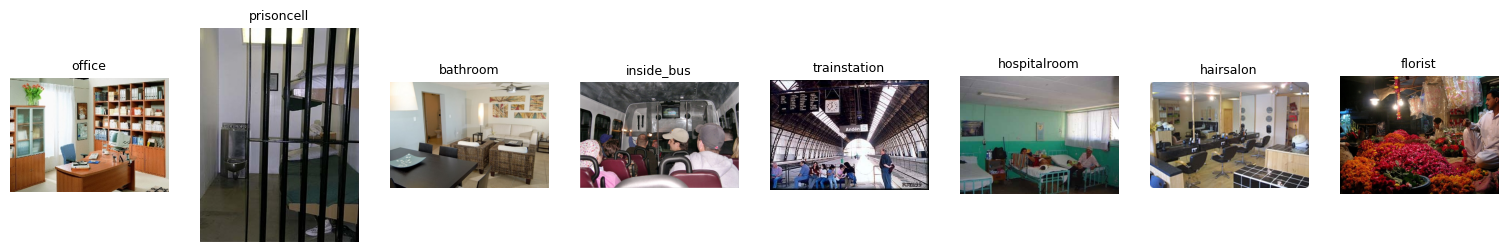

In [ ]:
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image                         #biblioteca de procesamiento de imágenes en Python

N_TRAIN_POR_CLASE = 30     # None = usar todo el conjunto de entrenamiento
N_VAL_POR_CLASE   = 20     # None = usar toda la validación

def submuestra(d, max_por_clase, semilla=0):
    """Índices de a lo sumo `max_por_clase` imágenes por clase (reproducible)."""
    etiquetas = np.array(d[COL_LABEL])
    if max_por_clase is None:
        return np.arange(len(etiquetas))
    rng = np.random.default_rng(semilla)
    idx = [rng.permutation(np.where(etiquetas == k)[0])[:max_por_clase] for k in np.unique(etiquetas)]
    return np.sort(np.concatenate(idx))

class HFImagenes(torch.utils.data.Dataset):
    """Envuelve un split de Hugging Face como Dataset de PyTorch: devuelve (tensor, etiqueta)."""
    def __init__(self, d, indices, transform):
        self.d, self.indices, self.transform = d, list(indices), transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        ej = self.d[int(self.indices[i])]
        img = ej[COL_IMG].convert("RGB")           # algunas imágenes vienen en escala de grises/CMYK
        return self.transform(img), ej[COL_LABEL]

IDX_TRAIN = submuestra(ds_train, N_TRAIN_POR_CLASE)
IDX_VAL   = submuestra(ds_val,   N_VAL_POR_CLASE)
print(f"Usaremos {len(IDX_TRAIN)} imágenes de entrenamiento y {len(IDX_VAL)} de validación ({NUM_CLASES} clases).")

# Ejemplos: una imagen de 8 clases distintas
rng = random.Random(0)
clases_ej = rng.sample(range(NUM_CLASES), k=min(8, NUM_CLASES))
fig, ax = plt.subplots(1, len(clases_ej), figsize=(2.4 * len(clases_ej), 3))
for a, k in zip(np.atleast_1d(ax), clases_ej):
    i = int(np.where(np.array(ds_train[COL_LABEL]) == k)[0][0])
    a.imshow(ds_train[i][COL_IMG].convert("RGB")); a.set_title(CLASES[k], fontsize=9); a.axis("off")
plt.show()

## Modelos preentrenados

https://github.com/BVLC/caffe/wiki/Model-Zoo



## 1. Ejemplo ResNet18

https://docs.pytorch.org/vision/stable/models.html


Una ResNet-18 tiene **≈ 11.7 millones de parámetros**. Nuestra submuestra de entrenamiento tiene **unos pocos miles de imágenes** (`N_TRAIN_POR_CLASE` × número de clases, ver celda anterior), es decir, del orden de **miles de parámetros por cada imagen** (y con solo unas decenas de imágenes por clase). Si entrenamos desde pesos aleatorios, el modelo puede memorizar el conjunto de entrenamiento sin aprender nada general.

**Transferencia de aprendizaje** = reutilizar lo que un modelo aprendió en una **tarea fuente** con muchos datos (p. ej., ImageNet: 1.28 M imágenes, 1000 clases) para resolver una **tarea destino** con pocos datos.

Formalmente: un modelo es la composición $f(x) = h\big(\phi(x)\big)$, donde $\phi$ es el **cuerpo** o *backbone* (capas convolucionales que producen una representación) y $h$ es la **cabeza** (clasificador). La hipótesis central es que $\phi$, aprendida en la tarea fuente, produce características útiles también para la tarea destino.


| Escenario | Qué se entrena | Cuándo |
|---|---|---|
| **Feature extraction** | Solo una cabeza nueva $h$; $\phi$ queda **congelada** | Muy pocos datos y dominio parecido |
| **Fine-tuning** | $h$ y parte (o todo) $\phi$, con *learning rate* pequeño | Datos moderados, o dominio distinto |
| **Desde cero** | Todo, con pesos aleatorios | Muchos datos **y** dominio muy distinto |

In [ ]:
import torch
from torchvision import models

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PESOS = models.ResNet18_Weights.IMAGENET1K_V1
pre = models.resnet18(weights=PESOS).eval().to(DEVICE)    # arquitectura + pesos aprendidos en ImageNet
azar = models.resnet18(weights=None).eval().to(DEVICE)    # misma arquitectura, pesos aleatorios
PREPRO = PESOS.transforms()                               # preprocesamiento imagen de entrada debe coincidir con el del preentrenamiento!
CATEGORIAS = PESOS.meta["categories"]

print("Preprocesamiento asociado a los pesos:\n", PREPRO)
print("\nParámetros:", f"{PESOS.meta['num_params']:,}")
print("Desempeño reportado en ImageNet-1K:", PESOS.meta["_metrics"]["ImageNet-1K"])

Preprocesamiento asociado a los pesos:
 ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

Parámetros: 11,689,512
Desempeño reportado en ImageNet-1K: {'acc@1': 69.758, 'acc@5': 89.078}


## 2. Reutilización de características: ¿qué aprendió la red?

En el [blog de Chris Olah](https://colah.github.io/) y en [Distill: *Feature Visualization*](https://distill.pub/2017/feature-visualization/) se muestra que las CNN aprenden una **jerarquía**: las primeras capas detectan bordes y colores, las intermedias texturas y patrones, y las profundas partes de objetos. Las primeras capas son casi **universales** (sirven para cualquier imagen natural); las últimas son **específicas** de la tarea fuente. Esta observación (Yosinski et al., 2014) es la base de todas las decisiones de *transfer learning*: congelar lo general, adaptar lo específico.

### 2.1 Filtros de la primera capa: preentrenados vs. aleatorios

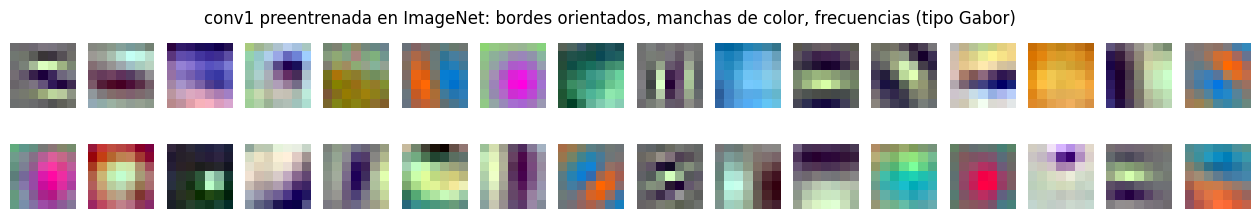

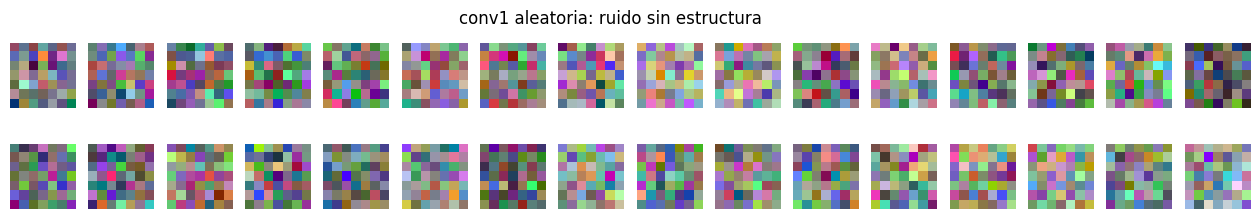

In [ ]:
def mostrar_filtros(modelo, titulo):
    w = modelo.conv1.weight.detach().cpu()[:32]                     # Primera convolución (32, 3, 7, 7)
    w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True) + 1e-8)
    fig, ax = plt.subplots(2, 16, figsize=(16, 2.4))
    for i, a in enumerate(ax.flat):
        a.imshow(w[i].permute(1, 2, 0)); a.axis("off")
    fig.suptitle(titulo); plt.show()

mostrar_filtros(pre, "conv1 preentrenada en ImageNet: bordes orientados, manchas de color, frecuencias (tipo Gabor)")
mostrar_filtros(azar, "conv1 aleatoria: ruido sin estructura")

### 2.2 Mapas de activación a lo largo de la red

Usamos *forward hooks* para capturar la salida de cada bloque. Observa cómo **baja la resolución espacial** y **suben los canales**: la red cambia "dónde" por "qué".

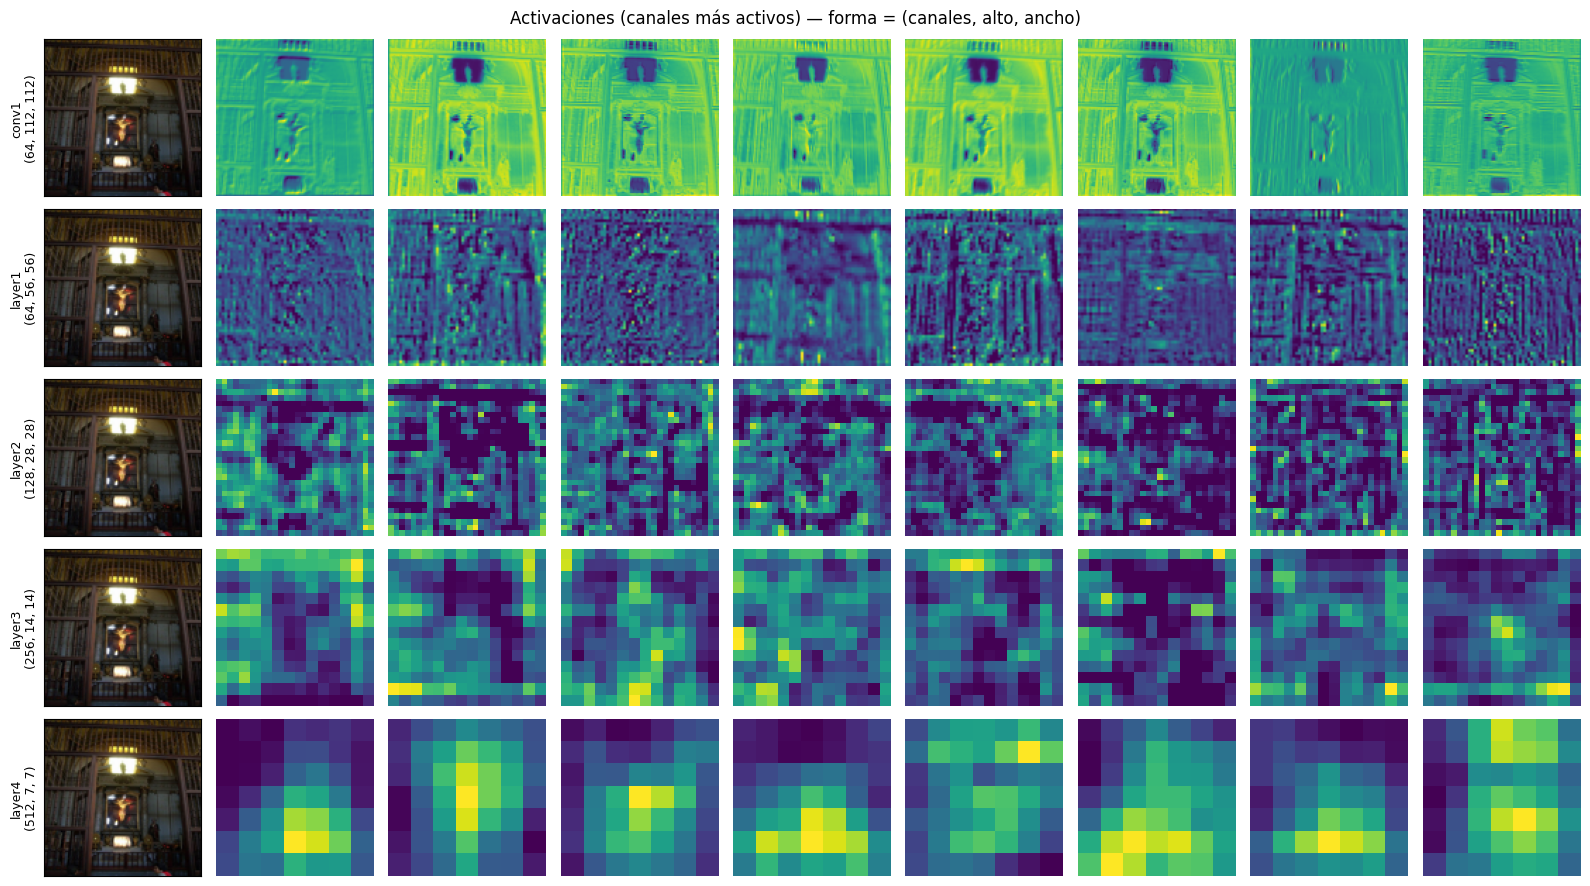

Top-5 de ImageNet para esta imagen:
  bookshop                  0.196
  altar                     0.160
  restaurant                0.141
  church                    0.113
  library                   0.071


In [ ]:
import torch.nn.functional as F

img_pil = ds_val[int(IDX_VAL[3])][COL_IMG].convert("RGB")                 # una imagen de validación
x_img = PREPRO(img_pil).unsqueeze(0).to(DEVICE) #aplicamos transformación

activaciones = {}
ganchos = [getattr(pre, n).register_forward_hook(lambda m, i, o, n=n: activaciones.__setitem__(n, o.detach().cpu()))
           for n in ["conv1", "layer1", "layer2", "layer3", "layer4"]]
with torch.no_grad():
    logits = pre(x_img)
for g in ganchos: g.remove()

fig, ax = plt.subplots(5, 9, figsize=(16, 9))
for f, (nombre, a) in enumerate(activaciones.items()):
    ax[f, 0].imshow(img_pil.resize((112, 112))); ax[f, 0].set_ylabel(f"{nombre}\n{tuple(a.shape[1:])}", fontsize=9)
    ax[f, 0].set_xticks([]); ax[f, 0].set_yticks([])
    canales = a[0].mean(dim=(1, 2)).argsort(descending=True)[:8]          # los 8 canales más activos
    for j, c in enumerate(canales):
        ax[f, j + 1].imshow(a[0, c], cmap="viridis"); ax[f, j + 1].axis("off")
plt.suptitle("Activaciones (canales más activos) — forma = (canales, alto, ancho)"); plt.tight_layout(); plt.show()

prob = F.softmax(logits, 1)[0].cpu()
top = prob.topk(5)
print("Top-5 de ImageNet para esta imagen:")
for p, i in zip(top.values, top.indices):
    print(f"  {CATEGORIAS[i]:<25s} {p:.3f}")

## 3. Anatomía de un modelo preentrenado: cuerpo y cabeza

En torchvision, la ResNet tiene sus bloques como atributos: `conv1, bn1, relu, maxpool, layer1…layer4, avgpool, fc`. La cabeza es `fc` (512 → 1000 clases de ImageNet). **Para nuestra tarea la reemplazamos** por una capa nueva de 512 → `NUM_CLASES` (el número de escenas del dataset).

**Congelar** un parámetro = `p.requires_grad = False`: autograd no calcula su gradiente y el optimizador no lo modifica.

In [ ]:
filas = []
for nombre, hijo in pre.named_children():
    filas.append({"bloque": nombre, "tipo": hijo.__class__.__name__,
                  "parámetros": sum(p.numel() for p in hijo.parameters())})
tabla = pd.DataFrame(filas)
tabla["% del total"] = (100 * tabla["parámetros"] / tabla["parámetros"].sum()).round(1)
display(tabla)
print("Observa: layer4 concentra ~75 % de los parámetros y la cabeza fc solo ~4 %.")

,bloque,tipo,parámetros,% del total
0,conv1,Conv2d,9408,0.1
1,bn1,BatchNorm2d,128,0.0
2,relu,ReLU,0,0.0
3,maxpool,MaxPool2d,0,0.0
4,layer1,Sequential,147968,1.3
5,layer2,Sequential,525568,4.5
6,layer3,Sequential,2099712,18.0
7,layer4,Sequential,8393728,71.8
8,avgpool,AdaptiveAvgPool2d,0,0.0
9,fc,Linear,513000,4.4


Observa: layer4 concentra ~75 % de los parámetros y la cabeza fc solo ~4 %.


## 4. *Feature extraction*: el cuerpo congelado como "traductor" de imágenes a vectores

Si congelamos todo el cuerpo, la red se vuelve una función fija $\phi: \text{imagen} \mapsto \mathbb{R}^{512}$. Entonces **podemos calcular las características una sola vez** y entrenar cualquier clasificador clásico encima (aquí, regresión logística). Esto es exactamente el escenario *ConvNet as fixed feature extractor*, y es la misma idea que usa el [Colab de CNN-LSTM de AMLD](https://colab.research.google.com/github/ahug/amld-pytorch-workshop/blob/master/5-CNN-LSTM.ipynb): una CNN preentrenada convierte cada frame en un vector y la LSTM trabaja sobre esa secuencia de vectores.

Comparamos el **mismo procedimiento** con el cuerpo preentrenado y con el cuerpo aleatorio.

In [ ]:
def extraer_embeddings(modelo, d, indices):
    ds_t = HFImagenes(d, indices, PREPRO)
    dl = torch.utils.data.DataLoader(ds_t, batch_size=32, shuffle=False, num_workers=2)
    cuerpo = nn.Sequential(*list(modelo.children())[:-1]).eval()    # todo excepto fc → (N, 512, 1, 1)
    X, y = [], []
    with torch.no_grad():
        for xb, yb in dl:
            X.append(cuerpo(xb.to(DEVICE)).flatten(1).cpu()); y.append(yb)
    return torch.cat(X).numpy(), torch.cat(y).numpy(), CLASES

t0 = time.time()
emb = {}
for etiqueta, modelo in [("preentrenado", pre), ("aleatorio", azar)]:
    Xtr, ytr, clases = extraer_embeddings(modelo, ds_train, IDX_TRAIN)
    Xva, yva, _ = extraer_embeddings(modelo, ds_val, IDX_VAL)
    emb[etiqueta] = (Xtr, ytr, Xva, yva)
print(f"Embeddings calculados en {time.time() - t0:.1f} s · forma: {Xtr.shape} · {len(clases)} clases")

resultados = []
for etiqueta, (Xtr, ytr, Xva, yva) in emb.items():
    clf = LogisticRegression(max_iter=3000).fit(Xtr, ytr)
    resultados.append({"cuerpo": etiqueta, "exactitud entrenamiento": clf.score(Xtr, ytr), "exactitud validación": clf.score(Xva, yva)})
display(pd.DataFrame(resultados).round(3))
print(f"Exactitud del azar con {NUM_CLASES} clases: {1 / NUM_CLASES:.3f}")

Embeddings calculados en 626.2 s · forma: (2010, 512) · 67 clases


,cuerpo,exactitud entrenamiento,exactitud validación
0,preentrenado,0.998,0.622
1,aleatorio,0.692,0.113


Exactitud del azar con 67 clases: 0.015


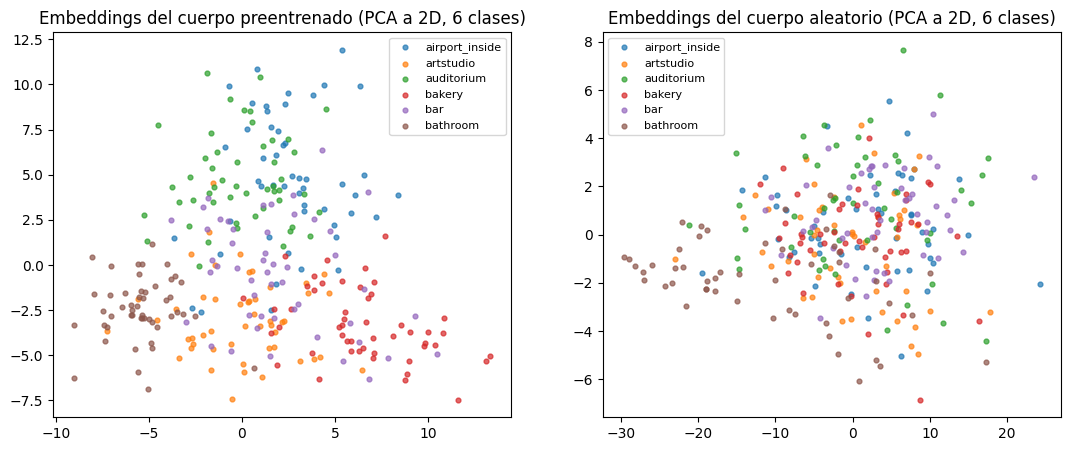

In [ ]:
# Con muchas clases una leyenda sería ilegible: graficamos solo 6 clases
CLASES_PCA = list(range(min(6, NUM_CLASES)))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (etiqueta, (Xtr, ytr, Xva, yva)) in zip(ax, emb.items()):
    Z = PCA(2).fit_transform(np.vstack([Xtr, Xva]))
    yy = np.concatenate([ytr, yva])
    for k in CLASES_PCA:
        a.scatter(Z[yy == k, 0], Z[yy == k, 1], s=12, alpha=.7, label=CLASES[k])
    a.set_title(f"Embeddings del cuerpo {etiqueta} (PCA a 2D, {len(CLASES_PCA)} clases)"); a.legend(fontsize=8)
plt.show()

### 4.1 ¿Cuántos datos necesitamos? Curva de aprendizaje con *feature extraction*

Como las características ya están calculadas, podemos repetir el experimento con **1, 2, 5, 10, 20, 50 y todas** las imágenes por clase disponibles en segundos. Esto nos da evidencia directa para el criterio "cantidad de datos".

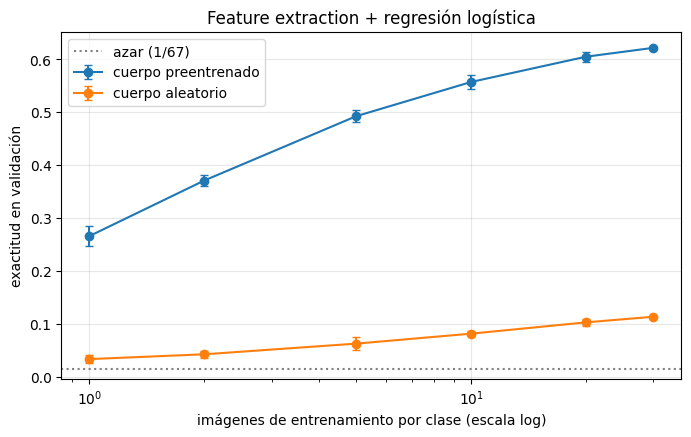

In [ ]:
def curva_aprendizaje(Xtr, ytr, Xva, yva, ns=(1, 2, 5, 10, 20, 50, 1000), repeticiones=5):
    rng = np.random.default_rng(0); filas = []
    n_max = int(np.bincount(ytr).min())                          # imágenes disponibles en la clase más pequeña
    ns = sorted({n for n in ns if n < n_max} | {n_max})          # la última entrada = "todas"
    for n in ns:
        for r in range(repeticiones):
            idx = np.concatenate([rng.permutation(np.where(ytr == k)[0])[:n] for k in np.unique(ytr)])
            acc = LogisticRegression(max_iter=3000).fit(Xtr[idx], ytr[idx]).score(Xva, yva)
            filas.append({"n_por_clase": n, "rep": r, "exactitud": acc})
    return pd.DataFrame(filas)

plt.figure(figsize=(8, 4.5))
for etiqueta, (Xtr, ytr, Xva, yva) in emb.items():
    c = curva_aprendizaje(Xtr, ytr, Xva, yva).groupby("n_por_clase").exactitud.agg(["mean", "std"])
    plt.errorbar(c.index, c["mean"], yerr=c["std"], marker="o", capsize=3, label=f"cuerpo {etiqueta}")
plt.xscale("log"); plt.axhline(1 / NUM_CLASES, ls=":", c="gray", label=f"azar (1/{NUM_CLASES})")
plt.xlabel("imágenes de entrenamiento por clase (escala log)"); plt.ylabel("exactitud en validación")
plt.title("Feature extraction + regresión logística"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 5. *Fine-tuning*: adaptar también el cuerpo

En *feature extraction* el cuerpo no cambia. En **fine-tuning** permitimos que algunas capas (o todas) se ajusten a la tarea destino. Tres decisiones de diseño:

1. **Qué capas descongelar.** Las últimas son las más específicas de ImageNet; si el dominio es parecido basta con `layer4`; si es distinto conviene descongelar más.
2. **Con qué *learning rate*.** Los pesos preentrenados ya están en una "buena región": un LR alto los destruye (*catastrophic forgetting*). Se usan **LR discriminativos**: la cabeza nueva aprende rápido (p. ej. $10^{-3}$) y el cuerpo lento ($10^{-4}$ a $10^{-5}$), más lento cuanto más temprana la capa.
3. **Cuándo descongelar.** **Descongelamiento progresivo** (Howard y Ruder, 2018): primero se entrena solo la cabeza (que empieza aleatoria y produce gradientes "ruidosos"); después se descongela `layer4`, luego `layer3`, etc. Así los gradientes grandes de una cabeza sin entrenar no dañan el cuerpo.

### 5.1 Tres configuraciones y su costo

In [ ]:
BLOQUES = ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]

def preparar_modelo(entrenables, num_clases=NUM_CLASES, pesos=PESOS):
    m = models.resnet18(weights=pesos)
    m.fc = nn.Linear(m.fc.in_features, num_clases)        # cabeza nueva, siempre aleatoria
    for nombre, hijo in m.named_children():
        for p in hijo.parameters():
            p.requires_grad = (entrenables == "todo") or (nombre in entrenables)
    return m.to(DEVICE)

def grupos_lr(m, lr_cabeza=1e-3, lr_cuerpo=1e-4):
    """Learning rates discriminativos: más pequeños cuanto más temprana es la capa."""
    escala = {"fc": lr_cabeza, "layer4": lr_cuerpo, "layer3": lr_cuerpo / 3, "layer2": lr_cuerpo / 10,
              "layer1": lr_cuerpo / 10, "conv1": lr_cuerpo / 10, "bn1": lr_cuerpo / 10}
    return [{"params": list(getattr(m, n).parameters()), "lr": lr, "nombre": n} for n, lr in escala.items()]

xb = torch.randn(32, 3, 224, 224, device=DEVICE); yb = torch.randint(0, NUM_CLASES, (32,), device=DEVICE)
filas = []
for modo, entr in [("feature extraction", ["fc"]), ("fine-tuning parcial", ["layer4", "fc"]), ("fine-tuning completo", "todo")]:
    m = preparar_modelo(entr).train()
    n_ent = sum(p.numel() for p in m.parameters() if p.requires_grad)
    F.cross_entropy(m(xb), yb).backward()                                   # calentamiento
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(5):
        m.zero_grad(); F.cross_entropy(m(xb), yb).backward()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    sin_grad = [n for n, p in m.named_parameters() if p.grad is None]
    filas.append({"modo": modo, "parámetros entrenables": f"{n_ent:,}", "% entrenable": round(100 * n_ent / sum(p.numel() for p in m.parameters()), 1),
                  "ms por iteración (fwd+bwd)": round((time.perf_counter() - t0) / 5 * 1000, 1),
                  "tensores sin gradiente": len(sin_grad)})
display(pd.DataFrame(filas))

,modo,parámetros entrenables,% entrenable,ms por iteración (fwd+bwd),tensores sin gradiente
0,feature extraction,"34,371",0.3,3082.8,60
1,fine-tuning parcial,"8,428,099",75.2,4181.7,45
2,fine-tuning completo,"11,210,883",100.0,8048.0,0


### 5.2 La trampa de BatchNorm al congelar

`requires_grad = False` congela los **pesos** γ y β de BatchNorm, pero **no** sus estadísticas `running_mean` y `running_var`: en modo `train()` se siguen actualizando con cada lote. Con lotes pequeños y un dominio distinto esto altera silenciosamente el cuerpo "congelado". Veámoslo:

In [ ]:
m = preparar_modelo(["fc"]).train()                            # todo congelado excepto fc
antes = m.layer1[0].bn1.running_mean.clone()
with torch.no_grad():
    m(torch.randn(8, 3, 224, 224, device=DEVICE) * 3 + 1)      # un lote con estadísticas muy distintas a ImageNet
print("¿Cambió running_mean de una capa 'congelada'?", not torch.allclose(antes, m.layer1[0].bn1.running_mean))

def bn_congeladas_en_eval(modelo):
    """Llamar DESPUÉS de modelo.train(): pone en eval() las BN cuyos parámetros están congelados."""
    for mod in modelo.modules():
        if isinstance(mod, nn.BatchNorm2d) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

m = preparar_modelo(["fc"]).train(); bn_congeladas_en_eval(m)
antes = m.layer1[0].bn1.running_mean.clone()
with torch.no_grad():
    m(torch.randn(8, 3, 224, 224, device=DEVICE) * 3 + 1)
print("Con bn_congeladas_en_eval → ¿cambió?", not torch.allclose(antes, m.layer1[0].bn1.running_mean))

¿Cambió running_mean de una capa 'congelada'? True
Con bn_congeladas_en_eval → ¿cambió? False


### 5.3 Plan de descongelamiento progresivo


In [ ]:
ETAPAS = [["fc"], ["layer4"], ["layer3"], ["layer2", "layer1", "conv1", "bn1"]]

def aplicar_etapa(modelo, epoca, epocas_por_etapa=2):
    etapa = min(epoca // epocas_por_etapa, len(ETAPAS) - 1)
    activos = [b for e in ETAPAS[: etapa + 1] for b in e]
    for nombre, hijo in modelo.named_children():
        for p in hijo.parameters():
            p.requires_grad = nombre in activos
    return etapa, activos

m = preparar_modelo(["fc"])
for ep in range(8):
    etapa, activos = aplicar_etapa(m, ep)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"época {ep}: etapa {etapa} · entrenables {n:>10,d} · bloques {activos}")
print("\nGrupos de LR discriminativos:", [(g["nombre"], g["lr"]) for g in grupos_lr(m)])

época 0: etapa 0 · entrenables     34,371 · bloques ['fc']
época 1: etapa 0 · entrenables     34,371 · bloques ['fc']
época 2: etapa 1 · entrenables  8,428,099 · bloques ['fc', 'layer4']
época 3: etapa 1 · entrenables  8,428,099 · bloques ['fc', 'layer4']
época 4: etapa 2 · entrenables 10,527,811 · bloques ['fc', 'layer4', 'layer3']
época 5: etapa 2 · entrenables 10,527,811 · bloques ['fc', 'layer4', 'layer3']
época 6: etapa 3 · entrenables 11,210,883 · bloques ['fc', 'layer4', 'layer3', 'layer2', 'layer1', 'conv1', 'bn1']
época 7: etapa 3 · entrenables 11,210,883 · bloques ['fc', 'layer4', 'layer3', 'layer2', 'layer1', 'conv1', 'bn1']

Grupos de LR discriminativos: [('fc', 0.001), ('layer4', 0.0001), ('layer3', 3.3333333333333335e-05), ('layer2', 1e-05), ('layer1', 1e-05), ('conv1', 1e-05), ('bn1', 1e-05)]


## 6. Selección del modelo base según el dominio

Elegir el *backbone* es una decisión de ingeniería con tres ejes: **qué tan parecido es el dominio de preentrenamiento**, **cuánto cómputo hay** (entrenamiento e inferencia) y **qué tan bueno es el modelo en su tarea fuente**. torchvision guarda metadatos de cada conjunto de pesos (sin descargar nada):

,modelo,pesos,parámetros (M),acc@1 ImageNet,GFLOPS,archivo (MB),resolución
0,mobilenet_v3_small,IMAGENET1K_V1,2.5,67.668,0.057,9.829,224
4,efficientnet_b0,IMAGENET1K_V1,5.3,77.692,0.386,20.451,224
1,mobilenet_v3_large,IMAGENET1K_V2,5.5,75.274,0.217,21.107,224
6,regnet_y_800mf,IMAGENET1K_V2,6.4,78.828,0.834,24.774,224
2,resnet18,IMAGENET1K_V1,11.7,69.758,1.814,44.661,224
5,efficientnet_b3,IMAGENET1K_V1,12.2,82.008,1.827,47.184,300
3,resnet50,IMAGENET1K_V2,25.6,80.858,4.089,97.790,224
8,swin_t,IMAGENET1K_V1,28.3,81.474,4.491,108.190,224
7,convnext_tiny,IMAGENET1K_V1,28.6,82.520,4.456,109.119,224
9,vit_b_16,IMAGENET1K_V1,86.6,81.072,17.564,330.285,224


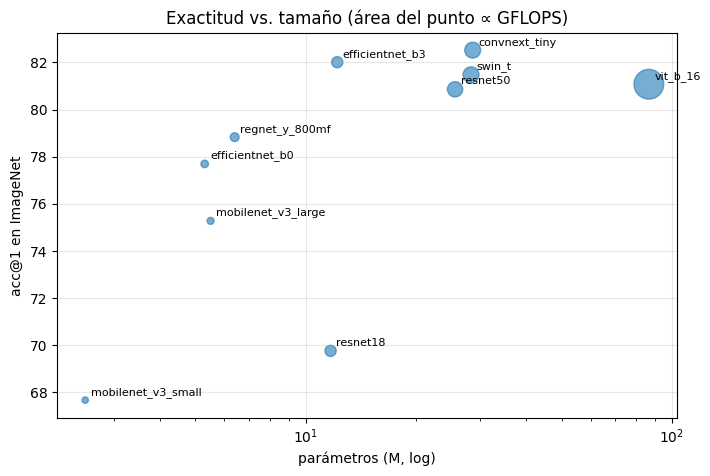

In [ ]:
filas = []
for nombre in ["mobilenet_v3_small", "mobilenet_v3_large", "resnet18", "resnet50", "efficientnet_b0",
               "efficientnet_b3", "regnet_y_800mf", "convnext_tiny", "swin_t", "vit_b_16"]:
    w = models.get_model_weights(nombre).DEFAULT
    filas.append({"modelo": nombre, "pesos": w.name, "parámetros (M)": round(w.meta["num_params"] / 1e6, 1),
                  "acc@1 ImageNet": w.meta["_metrics"]["ImageNet-1K"]["acc@1"],
                  "GFLOPS": w.meta.get("_ops"), "archivo (MB)": w.meta.get("_file_size"),
                  "resolución": w.transforms().crop_size[0]})
cat = pd.DataFrame(filas).sort_values("parámetros (M)")
display(cat)

plt.figure(figsize=(8, 5))
plt.scatter(cat["parámetros (M)"], cat["acc@1 ImageNet"], s=cat["GFLOPS"].fillna(1) * 25 + 20, alpha=.6)
for _, f in cat.iterrows():
    plt.annotate(f.modelo, (f["parámetros (M)"], f["acc@1 ImageNet"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xscale("log"); plt.xlabel("parámetros (M, log)"); plt.ylabel("acc@1 en ImageNet")
plt.title("Exactitud vs. tamaño (área del punto ∝ GFLOPS)"); plt.grid(alpha=.3); plt.show()

### 6.1 Más allá de ImageNet: modelos especializados

| Dominio de tu problema | Punto de partida razonable | Por qué |
|---|---|---|
| Fotos "naturales" (objetos, animales, escenas) | Pesos ImageNet de torchvision o [timm](https://huggingface.co/docs/timm) (ResNet, EfficientNet, ConvNeXt) | Dominio casi idéntico |
| Imagen médica (rayos X, ultrasonido, TC) | Modelos preentrenados en imagen médica (p. ej. RadImageNet, BiomedCLIP) o auto-supervisados | Texturas y estadísticas de intensidad muy distintas a ImageNet; a menudo escala de grises |
| Percepción remota (satélite, dron) | Modelos geoespaciales (p. ej. Prithvi de NASA/IBM, SatlasPretrain) | Más de 3 bandas espectrales, vista cenital, sin "objeto centrado" |
| Propósito general / pocos datos | Modelos auto-supervisados (familia DINOv2) o de visión-lenguaje (CLIP, SigLIP) | Características muy transferibles; algunos permiten clasificación *zero-shot* |
| Tiempo real / dispositivo móvil | MobileNetV3, EfficientNet-B0, versiones *nano* | Pocos GFLOPS; ver Unidad 2 (YOLO nano) |

**Regla práctica:** empieza con el modelo **más pequeño que sea razonable** y un *baseline* de *feature extraction*. Solo si no alcanza, sube de tamaño o cambia de dominio de preentrenamiento. Cuando cambies de modelo, cambia también su preprocesamiento (`weights.transforms()`).


## 7. Criterios de decisión: cantidad de datos × similitud de tarea


| | **Dominio parecido** a la fuente | **Dominio distinto** a la fuente |
|---|---|---|
| **Pocos datos** | *Feature extraction* (cabeza lineal sobre el cuerpo congelado). Hacer fine-tuning arriesga sobreajuste | Lo más difícil. Usar características de capas **intermedias** (más genéricas), *fine-tuning* muy cuidadoso, aumento de datos; buscar un modelo preentrenado del dominio |
| **Muchos datos** | *Fine-tuning* de varias capas o de todo con LR pequeño | *Fine-tuning* completo; entrenar desde cero se vuelve viable, pero inicializar con pesos preentrenados casi nunca empeora |

Otros factores que también pesan: **costo de cómputo**, **latencia** en inferencia, **resolución** de las imágenes y **licencia** de los pesos.

**Para este dataset (escenas de interiores):** las fotos son "naturales" y ImageNet contiene muchos objetos de interior (camas, sillas, hornos), pero la etiqueta es la **escena completa**, no un objeto. La similitud de dominio es **media-alta**, así que *feature extraction* es un buen baseline y el *fine-tuning* de `layer4` suele aportar la mejora siguiente.

## 8. Transferencia de estilo neuronal: otra forma de "transferir"

Gatys, Ecker y Bethge (2016) mostraron que las características de una CNN preentrenada (VGG-19) separan **contenido** y **estilo**:

* **Contenido** = las activaciones $F^\ell$ de una capa profunda (qué objetos hay y dónde).
* **Estilo** = las correlaciones entre canales, la **matriz de Gram** $G^\ell_{ij} = \frac{1}{C H W}\sum_{k} F^\ell_{ik} F^\ell_{jk}$, que conserva texturas y colores pero **descarta la posición**.

Se parte de una imagen y se optimizan **sus píxeles** (¡no los pesos de la red, que quedan congelados!) para minimizar
$$\mathcal{L} = \alpha\, \lVert F^{\ell_c}(x) - F^{\ell_c}(x_c) \rVert^2 + \beta \sum_{\ell \in S} \lVert G^\ell(x) - G^\ell(x_s) \rVert^2 .$$

Es *transfer learning* en el sentido más puro: una red entrenada para clasificar se reutiliza, sin cambiarla, como **función de pérdida perceptual**. En clase abriremos el [tutorial de TensorFlow](https://www.tensorflow.org/tutorials/generative/style_transfer) (*Run in Google Colab*) para ver la versión rápida de TF-Hub. Aquí calculamos la matriz de Gram para entender por qué "olvida" la posición:

In [ ]:
def gram(F_):                                  # F_: (1, C, H, W)
    _, c, h, w = F_.shape
    f = F_.view(c, h * w)
    return f @ f.t() / (c * h * w)

a = activaciones["layer1"]                     # (1, 64, 56, 56) de la imagen de validación
a_rev = a[:, :, torch.randperm(56), :][:, :, :, torch.randperm(56)]   # mismos valores, posiciones REVUELTAS
print("Diferencia en activaciones (contenido):", (a - a_rev).abs().mean().item())
print("Diferencia en matriz de Gram (estilo):  ", (gram(a) - gram(a_rev)).abs().mean().item())

Diferencia en activaciones (contenido): 0.4553859829902649
Diferencia en matriz de Gram (estilo):   3.3099212259912747e-10


## 9. Cierre

**Ideas**
1. Las CNN aprenden una jerarquía: capas tempranas genéricas, capas tardías específicas. Eso permite **reutilizar** el cuerpo.
2. *Feature extraction* = cuerpo congelado + cabeza nueva. Es barato, robusto y el mejor *baseline* con pocos datos.
3. *Fine-tuning* = adaptar el cuerpo con LR pequeño y discriminativo; el **descongelamiento progresivo** protege los pesos preentrenados. Cuidado con BatchNorm.
4. El modelo base se elige por **dominio**, **cómputo** y **desempeño**, y su preprocesamiento viaja con él.
5. La decisión depende de **cantidad de datos × similitud**; la curva de aprendizaje es la evidencia que la sustenta.

**Proyecto integrador (Moodle)**
* **Ficha de modelo base del proyecto integrador** (foro): dataset, número de imágenes por clase, similitud con ImageNet (alta/media/baja y por qué), dos *backbones*. Si tu dataset ya está en formato `train/` y `val/` por carpetas, súbelo a tu Drive: el jueves podrás usarlo en la práctica.



**Bibliografía**
* Ayyadevara, V. K., y Reddy, Y. (2024). *Modern Computer Vision with PyTorch* (2.ª ed., cap. 5). Packt.
* Gatys, L. A., Ecker, A. S., y Bethge, M. (2016). Image style transfer using convolutional neural networks. *CVPR*.
* Howard, J., y Ruder, S. (2018). Universal language model fine-tuning for text classification. *ACL*.
* Olah, C., Mordvintsev, A., y Schubert, L. (2017). Feature visualization. *Distill*.
* Yosinski, J., Clune, J., Bengio, Y., y Lipson, H. (2014). How transferable are features in deep neural networks? *NeurIPS*.